# Data Preprocessing

In [1]:
import sys
!{sys.executable} -m pip install pandas numpy matplotlib scikit-learn pyarrow


[notice] A new release of pip available: 22.3.1 -> 26.2.1
[notice] To update, run: pip3.11 install --upgrade pip


In [2]:
import pandas as pd
import numpy as np

dataset = pd.read_csv("diabetes_large_dataset.csv")

print(dataset)

      patient_id  record_id   age age_group     sex  gender        ethnicity  \
0        P000001  R00000001  57.0     51-60    Male    Male            Black   
1        P000002  R00000002  47.0     41-50  Female  Female            White   
2        P000003  R00000003  59.0     51-60    Male    Male            Black   
3        P000004  R00000004  72.0     71-90  Female  Female            Black   
4        P000005  R00000005  46.0     41-50    Male    Male         Hispanic   
...          ...        ...   ...       ...     ...     ...              ...   
99995    P099996  R00099996  46.0     41-50    Male    Male            Black   
99996    P099997  R00099997  41.0     41-50  Female  Female            Asian   
99997    P099998  R00099998  56.0     51-60  Female  Female            White   
99998    P099999  R00099999  46.0     41-50  Female  Female            White   
99999    P100000  R00100000  51.0     51-60  Female  Female  Native American   

            race_group marital_status e

## Select and encode variables

Keep the 12 predictors and the outcome. `family_history_diabetes` (Yes/No) becomes 0/1 and `stress_level` is encoded as an ordinal scale (Low=0 … Very High=3). Rows where `diabetes_status` itself is missing can't be used to train or evaluate a classifier, so they are dropped.

In [3]:
predictors = [
    "bmi", "age", "systolic_bp", "family_history_diabetes", "cigarettes_per_day",
    "alcohol_units_per_week", "exercise_minutes_per_week", "sedentary_hours_per_day",
    "sleep_hours", "stress_level", "added_sugar_grams_per_day", "fiber_grams_per_day",
]
target = "diabetes_status"

model_df = dataset[predictors + [target]].copy()
model_df["family_history_diabetes"] = model_df["family_history_diabetes"].map({"No": 0, "Yes": 1})
model_df["stress_level"] = model_df["stress_level"].map(
    {"Low": 0, "Moderate": 1, "High": 2, "Very High": 3}
)

print("Rows with missing target:", model_df[target].isna().sum())
model_df = model_df.dropna(subset=[target]).copy()
model_df[target] = model_df[target].astype(int)

X = model_df[predictors]
y = model_df[target]
print("Modeling dataset:", model_df.shape)

Rows with missing target: 2020
Modeling dataset: (97980, 13)


## Missingness

Percent missing per predictor, then compared across outcome groups. If the rates differ by `diabetes_status`, the missingness is informative and dropping rows could bias the model.

In [ ]:
missing_pct = X.isna().mean().mul(100).round(2).rename("pct_missing")
print(missing_pct[missing_pct > 0].sort_values(ascending=False))

# % missing within each diabetes_status group
by_outcome = X.isna().groupby(y).mean().mul(100).round(2).T
by_outcome.columns = ["no_diabetes_pct_missing", "diabetes_pct_missing"]
by_outcome[by_outcome.sum(axis=1) > 0]

sleep_hours     4.98
stress_level    4.90
bmi             2.02
age             1.99
systolic_bp     1.94
Name: pct_missing, dtype: float64


,no_diabetes_pct_missing,diabetes_pct_missing
bmi,2.01,2.06
age,1.99,2.00
systolic_bp,1.91,2.02
sleep_hours,4.92,5.11
stress_level,4.96,4.73


## Class balance, duplicates, and range checks

Class balance determines which metrics make sense (AUC, recall, F1 rather than accuracy alone). Ranges are checked for impossible values.

In [5]:
print("Class balance (diabetes_status):")
print(y.value_counts().to_frame("count").assign(share=y.value_counts(normalize=True).round(4)))

print("\nDuplicate rows:", dataset.duplicated().sum(), "| duplicate patient_id:", dataset["patient_id"].duplicated().sum())

print("\nSummary statistics / range check:")
model_df[predictors].describe().T[["min", "25%", "50%", "75%", "max"]].round(2)

Class balance (diabetes_status):
                 count   share
diabetes_status               
0                70573  0.7203
1                27407  0.2797

Duplicate rows: 0 | duplicate patient_id: 0

Summary statistics / range check:


,min,25%,50%,75%,max
bmi,9.94,23.95,27.88,31.91,59.69
age,18.00,39.00,50.00,60.00,90.00
systolic_bp,80.00,114.00,124.00,133.00,219.86
family_history_diabetes,0.00,0.00,0.00,1.00,1.00
cigarettes_per_day,0.00,0.00,0.00,0.00,51.00
alcohol_units_per_week,0.00,0.00,1.20,9.50,47.30
exercise_minutes_per_week,0.00,0.00,42.00,85.00,462.00
sedentary_hours_per_day,1.00,5.70,6.80,7.90,14.40
sleep_hours,3.00,6.20,7.00,7.80,12.00
stress_level,0.00,0.00,1.00,2.00,3.00


## Correlation and multicollinearity

Correlation matrix of the predictors only, plus VIF. Pairs with |r| above roughly 0.7 or VIF above 5 would make logistic regression coefficients unstable. The last output shows each predictor's univariate association with the outcome.

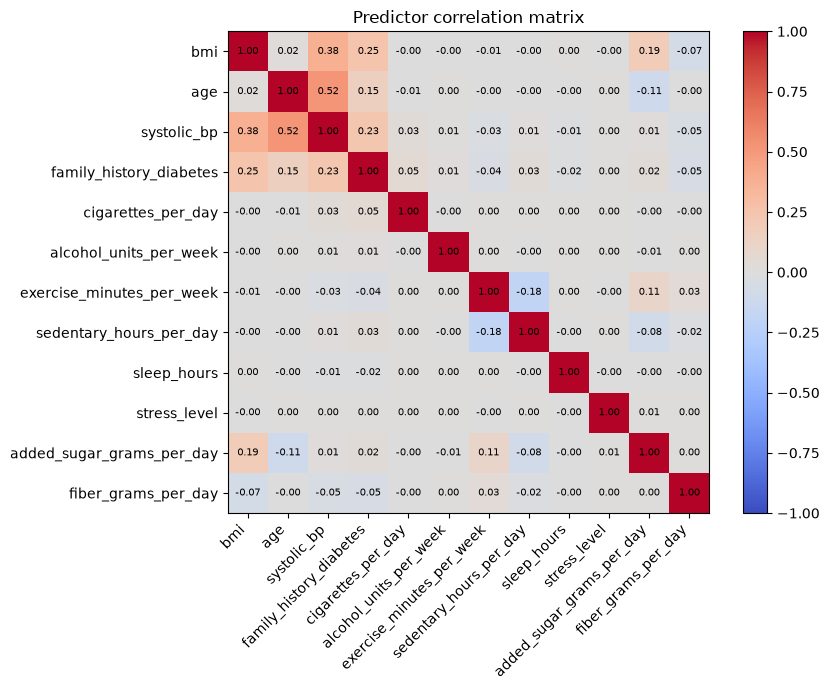

age                        systolic_bp                  0.518
bmi                        systolic_bp                  0.376
                           family_history_diabetes      0.248
systolic_bp                family_history_diabetes      0.227
bmi                        added_sugar_grams_per_day    0.185
exercise_minutes_per_week  sedentary_hours_per_day     -0.183
age                        family_history_diabetes      0.150
                           added_sugar_grams_per_day   -0.107
dtype: float64

VIF (complete cases, n = 83382 )
systolic_bp                  1.69
age                          1.47
bmi                          1.32
family_history_diabetes      1.10
added_sugar_grams_per_day    1.07
exercise_minutes_per_week    1.05
sedentary_hours_per_day      1.04
cigarettes_per_day           1.01
fiber_grams_per_day          1.01
alcohol_units_per_week       1.00
sleep_hours                  1.00
stress_level                 1.00
Name: VIF, dtype: float64

Correlation with dia

In [ ]:
import matplotlib.pyplot as plt

corr = X.corr()  # pairwise-complete; predictors only, outcome excluded

fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(predictors)), predictors, rotation=45, ha="right")
ax.set_yticks(range(len(predictors)), predictors)
for i in range(len(predictors)):
    for j in range(len(predictors)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
fig.colorbar(im, ax=ax)
ax.set_title("Predictor correlation matrix")
plt.tight_layout()
plt.show()

# Strongest off-diagonal pairs
pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
print(pairs.reindex(pairs.abs().sort_values(ascending=False).index).head(8).round(3))

# VIF on complete cases: diagonal of the inverse correlation matrix
cc = X.dropna()
vif = pd.Series(np.diag(np.linalg.inv(cc.corr().values)), index=predictors, name="VIF").round(2)
print("\nVIF (complete cases, n =", len(cc), ")")
print(vif.sort_values(ascending=False))

print("\nCorrelation with diabetes_status")
print(X.corrwith(y).sort_values(key=abs, ascending=False).round(3))

## Train/test split and preprocessing

Split first (stratified on the outcome), then fit the imputer and scaler on the training set only. Median imputation is used because several predictors are right-skewed. Predictors are standardized so logistic regression coefficients are comparable.

In [7]:
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

# Fit on train only, then apply to both, so no test information leaks into training
imputer = SimpleImputer(strategy="median")
scaler = StandardScaler()

X_train_scaled = pd.DataFrame(
    scaler.fit_transform(imputer.fit_transform(X_train)),
    columns=predictors, index=X_train.index,
)
X_test_scaled = pd.DataFrame(
    scaler.transform(imputer.transform(X_test)),
    columns=predictors, index=X_test.index,
)

print(X_train_scaled.shape, X_test_scaled.shape)
print("Train prevalence:", round(y_train.mean(), 4), "| Test prevalence:", round(y_test.mean(), 4))
print("Remaining NaNs:", X_train_scaled.isna().sum().sum() + X_test_scaled.isna().sum().sum())

(78384, 12) (19596, 12)
Train prevalence: 0.2797 | Test prevalence: 0.2797
Remaining NaNs: 0


## Save outputs for the model notebooks

Both models load these files so they are trained and evaluated on the identical split. Rerunning this notebook overwrites them.

In [8]:
import os
import joblib

os.makedirs("data", exist_ok=True)

# Unscaled splits (NaNs kept): used by gradient boosting
X_train.to_parquet("data/X_train.parquet")
X_test.to_parquet("data/X_test.parquet")

# Imputed + standardized splits: used by logistic regression
X_train_scaled.to_parquet("data/X_train_scaled.parquet")
X_test_scaled.to_parquet("data/X_test_scaled.parquet")

# Targets (shared by both models)
y_train.to_frame().to_parquet("data/y_train.parquet")
y_test.to_frame().to_parquet("data/y_test.parquet")

# Fitted preprocessing objects, so new data can be transformed the same way
joblib.dump(imputer, "data/imputer.joblib")
joblib.dump(scaler, "data/scaler.joblib")

print(sorted(os.listdir("data")))

['X_test.parquet', 'X_test_scaled.parquet', 'X_train.parquet', 'X_train_scaled.parquet', 'imputer.joblib', 'scaler.joblib', 'y_test.parquet', 'y_train.parquet']
